# US School Choice and Homeschooling, 2016 and 2019, Starter Notebook

![cover](https://raw.githubusercontent.com/montessoritheory/us-school-choice-homeschooling/main/images/cover.png)

This notebook loads the harmonized NCES Parent and Family Involvement in Education files, one row per student from kindergarten to grade 12, and computes **weighted estimates with jackknife standard errors** for these questions.

1. How do children go to school, assigned public, chosen public, charter, private or homeschool?
2. Who homeschools, and why?
3. How satisfied are parents with each type of school?

Dataset by [Montessori Theory](https://www.montessori-theory.com/), CC BY 4.0. Source, NCES NHES.

In [1]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt

GITHUB = 'https://raw.githubusercontent.com/montessoritheory/us-school-choice-homeschooling/main/data'
hits = glob.glob('/kaggle/input/**/school_choice_homeschooling_2019.csv', recursive=True)
BASE = os.path.dirname(hits[0]) if hits else next((p for p in ['data', '../data'] if os.path.exists(f'{p}/school_choice_homeschooling_2019.csv')), GITHUB)

def rep_file(y):
    k = glob.glob(f'/kaggle/input/**/replicate_weights_{y}.*', recursive=True)
    return k[0] if k else f'{BASE}/replicate_weights_{y}.zip'

s = pd.concat([pd.read_csv(f'{BASE}/school_choice_homeschooling_{y}.csv', dtype={'student_id': str}).merge(pd.read_csv(rep_file(y), dtype={'student_id': str}), on=['survey_year', 'student_id']) for y in (2016, 2019)], ignore_index=True)
print(s.shape, s.survey_year.value_counts().to_dict())

(30521, 151) {2019: 16446, 2016: 14075}


In [2]:
R = 80
def pct(df, num):
    p = 100 * df.final_weight[num].sum() / df.final_weight.sum()
    reps = np.array([100 * df[f'FPWT{i}'][num].sum() / df[f'FPWT{i}'].sum() for i in range(1, R + 1)])
    return round(p, 1), round(np.sqrt((R - 1) / R * ((reps - p) ** 2).sum()), 2)

plt.rcParams.update({'figure.facecolor': '#F7F3EC', 'axes.facecolor': '#F7F3EC', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E4DED3', 'font.size': 12})
TC, BLUE, OLIVE, GOLD = '#B4532F', '#1F72B8', '#7F9A1F', '#D19A2A'
U = s[s.child_age.between(5, 17)]   # the NCES universe for homeschooling rates

## 1. Type of schooling

The 2016 homeschooling estimate reproduces the NCES Digest table 206.10 exactly (1.69 million, 3.3 %).

In [3]:
types = ['Public, assigned', 'Public, chosen', 'Public charter', 'Private, Catholic', 'Private, other religious', 'Private, nonreligious', 'Homeschooled']
tab = pd.DataFrame({y: [pct(g, g.schooling_type == t)[0] for t in types] for y, g in U.groupby('survey_year')}, index=types)
tab

,2016,2019
"Public, assigned",69.9,69.7
"Public, chosen",10.4,8.3
Public charter,7.0,8.2
"Private, Catholic",3.6,3.3
"Private, other religious",3.1,4.0
"Private, nonreligious",2.4,2.2
Homeschooled,3.3,2.9


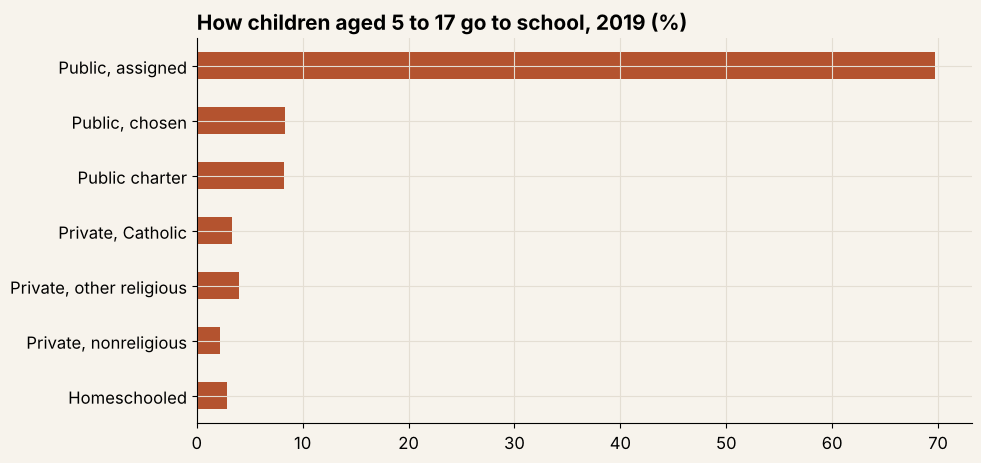

In [4]:
fig, ax = plt.subplots(figsize=(10, 5)); tab[2019][::-1].plot.barh(ax=ax, color=TC)
ax.set_title('How children aged 5 to 17 go to school, 2019 (%)', loc='left', fontsize=15, fontweight='bold'); plt.show()

## 2. Who homeschools, and why

In [5]:
y19 = U[U.survey_year == 2019]
for col in ['locale_group', 'census_region', 'child_race_ethnicity']:
    print(pd.DataFrame([[g, *pct(y19[y19[col] == g], y19[y19[col] == g].homeschooled == 'Yes')] for g in sorted(y19[col].dropna().unique())], columns=[col, 'percent_homeschooled', 'se']), '\n')

  locale_group  percent_homeschooled    se
0         City                   2.5  0.29
1        Rural                   4.8  0.53
2       Suburb                   2.5  0.25
3         Town                   2.5  0.42 

  census_region  percent_homeschooled    se
0       Midwest                   2.2  0.31
1     Northeast                   2.1  0.35
2         South                   3.4  0.29
3          West                   3.1  0.35 



                    child_race_ethnicity  percent_homeschooled    se
0                    Black, non-Hispanic                   1.2  0.36
1                               Hispanic                   2.1  0.33
2  Other or multiple races, non-Hispanic                   1.7  0.34
3                    White, non-Hispanic                   4.0  0.27 



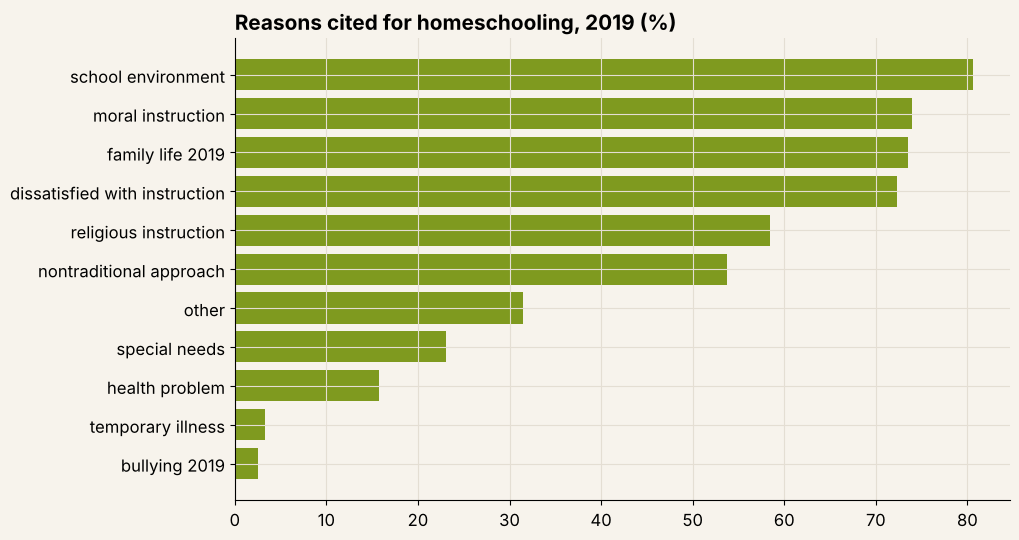

In [6]:
hs = y19[y19.homeschooled == 'Yes']
reasons = [c for c in s.columns if c.startswith('homeschool_reason_')]
r = pd.DataFrame([[c.replace('homeschool_reason_', '').replace('_', ' '), *pct(hs[hs[c].notna()], hs[hs[c].notna()][c] == 'Yes')] for c in reasons], columns=['reason', 'percent', 'se']).sort_values('percent')
fig, ax = plt.subplots(figsize=(10, 6)); ax.barh(r.reason, r.percent, color=OLIVE)
ax.set_title('Reasons cited for homeschooling, 2019 (%)', loc='left', fontsize=15, fontweight='bold'); plt.show()

## 3. Parent satisfaction by type of school

In [7]:
sat = pd.DataFrame([[t, *pct(y19[(y19.schooling_type == t) & y19.satisfaction_school.notna()], y19[(y19.schooling_type == t) & y19.satisfaction_school.notna()].satisfaction_school == 'Very satisfied')] for t in types[:-1]], columns=['schooling_type', 'percent_very_satisfied', 'se'])
sat

,schooling_type,percent_very_satisfied,se
0,"Public, assigned",60.6,0.64
1,"Public, chosen",67.4,2.04
2,Public charter,67.6,2.30
3,"Private, Catholic",75.4,2.76
4,"Private, other religious",83.4,2.16
5,"Private, nonreligious",81.7,2.65


## 4. Ideas to go further

- The 2019 `choice_reason_..._2019` columns tell why parents chose their school, so you can compare charter and private families.
- Relate parent involvement (`parent_...`) to satisfaction and to `child_enjoys_school`.
- Compare homeschool teaching styles (`homeschool_teaching_style`) with the reasons families give.

If you homeschool with Montessori, see the [Montessori homeschool schedule](https://www.montessori-theory.com/montessori-homeschool-schedule/) on Montessori Theory.